# Dataset Description
## Who runs Colombia's neighbourhood supermarkets? D1 vs the rest

**Source**: [DANE](https://www.datos.gov.co/Comercio-Industria-y-Turismo/Establecimientos-Agencias-Sucursales/nb3d-v3n7/about_data)

Active commercial establishments registered under CIIU 4711 (non-specialized retail, food predominating), as of 2026-11-12. The owner NIT was used to group stores by brand.

# Code
## Imports

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

## Load data

In [7]:
path = "./data/Establecimientos_-_Agencias_-_Sucursales_20261112.csv"

df = pd.read_csv(
    path, encoding="utf-8", dtype=str,
    usecols=["camara_comercio", "ultimo_ano_renovado", "fecha_matricula", "clase_identificacion_propietario", "numero_identificacion_propietario"],
)

## Clean Data

In [8]:
# Some NITs were typed with the check digit glued at the end (10 digits instead of 9)
nit = df["numero_identificacion_propietario"].str.lstrip("0")
df["nit"] = nit.where(nit.str.len() <= 9, nit.str[:-1])

brands = {
    "900276962": "D1",
    "900480569": "Ara",
    "900236520": "Oxxo",
    "890900608": "Éxito",
    "890107487": "Olímpica",
    "830095213": "Terpel\n(Altoque, Deuna)",
    "901613496": "Ísimo",
    "900155107": "Jumbo / Metro",
}

stores = df[
    df["clase_identificacion_propietario"].eq("NIT")
    & df["ultimo_ano_renovado"].astype(int).ge(2025)
    & df["nit"].isin(brands)
].copy()
stores["brand"] = stores["nit"].map(brands)
stores["year"] = stores["fecha_matricula"].str[:4].astype(int)

summary = stores.groupby("brand").agg(
    stores=("nit", "size"), chambers=("camara_comercio", "nunique")
).sort_values("stores")
summary

,stores,chambers
brand,,
Jumbo / Metro,82,30
Ísimo,342,20
"Terpel\n(Altoque, Deuna)",372,41
Olímpica,398,39
Éxito,444,45
Oxxo,703,20
Ara,1574,48
D1,2968,57


## Plot
### Registered stores per brand

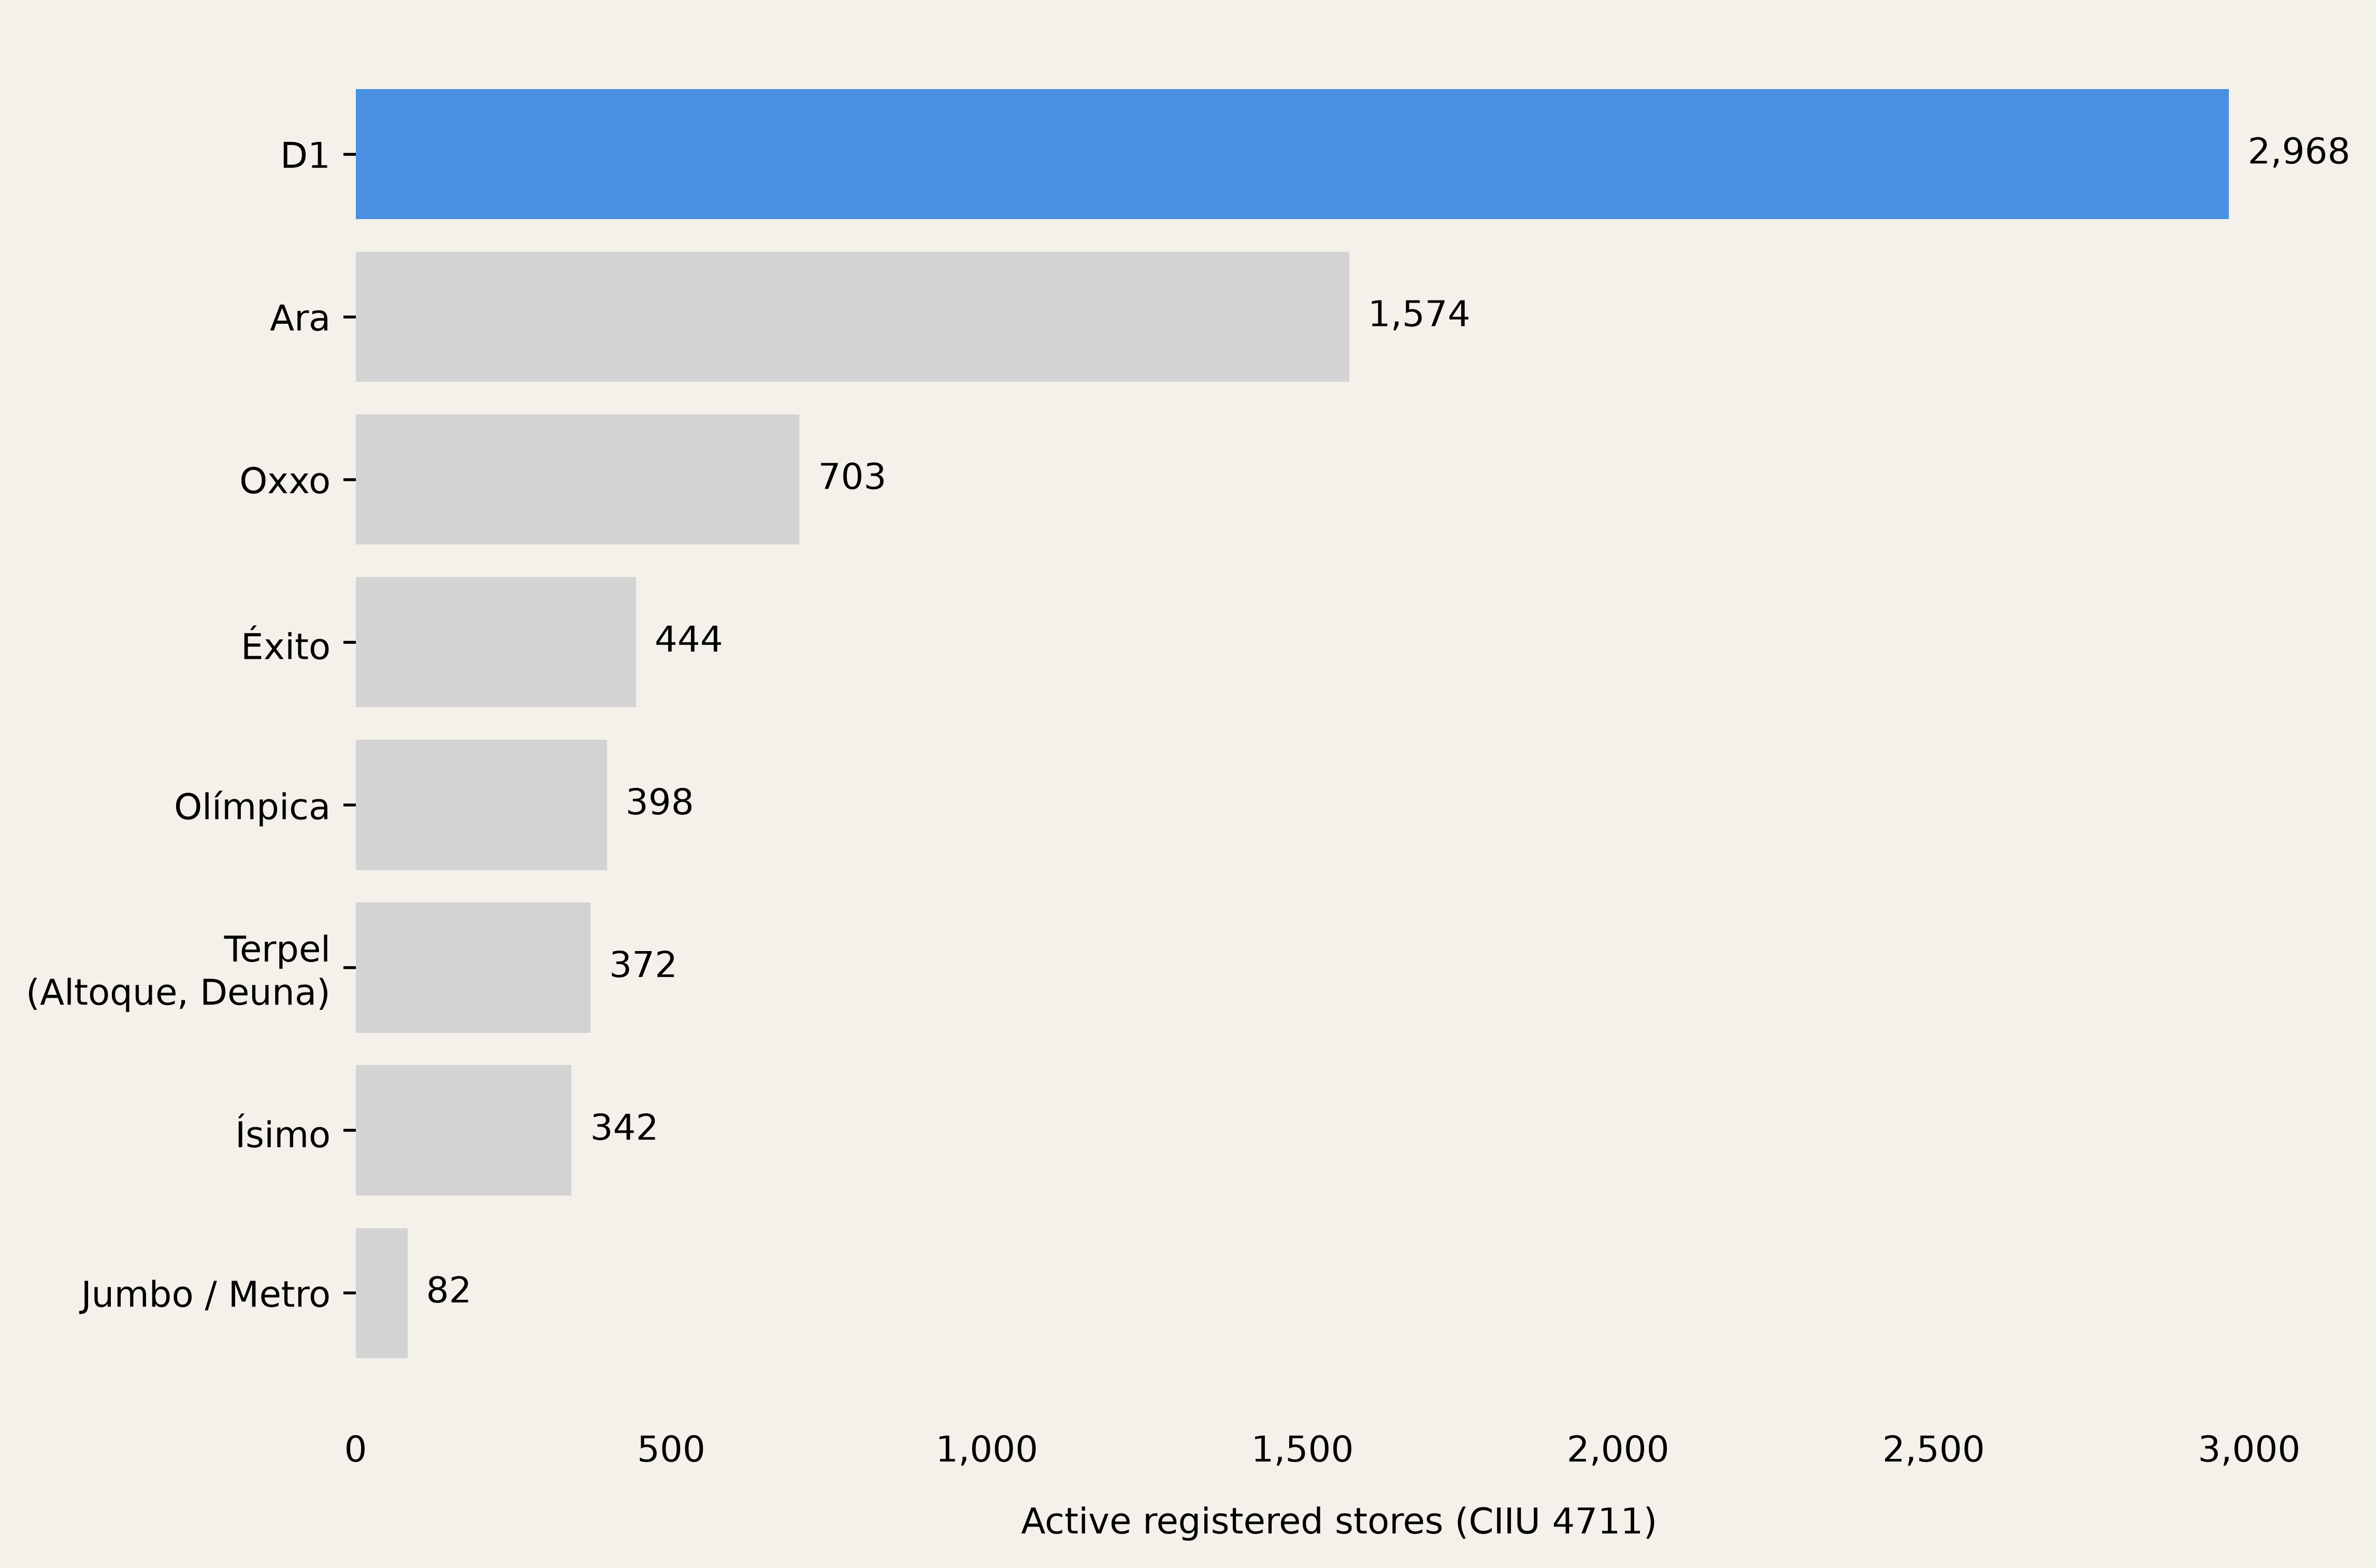

In [9]:
background = "#F4F1EA"
highlight = "#4a90e2"

plt.figure(figsize=(9.8, 7.0), dpi=500, facecolor=background)
plt.gca().set_facecolor(background)

colors = [highlight if b == "D1" else "#D3D3D3" for b in summary.index]
bars = plt.barh(summary.index, summary["stores"], color=colors)

offset = summary["stores"].max() * 0.01
for b, v, c in zip(bars, summary["stores"], summary["chambers"]):
    plt.text(v + offset, b.get_y() + b.get_height() / 2, f"{v:,}", va="center")

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

plt.tick_params(axis="x", length=0)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}" if x != 0 else "0"))
plt.xlabel("Active registered stores (CIIU 4711)", labelpad=10, fontsize=10)

plt.show()

### Growth by registration year

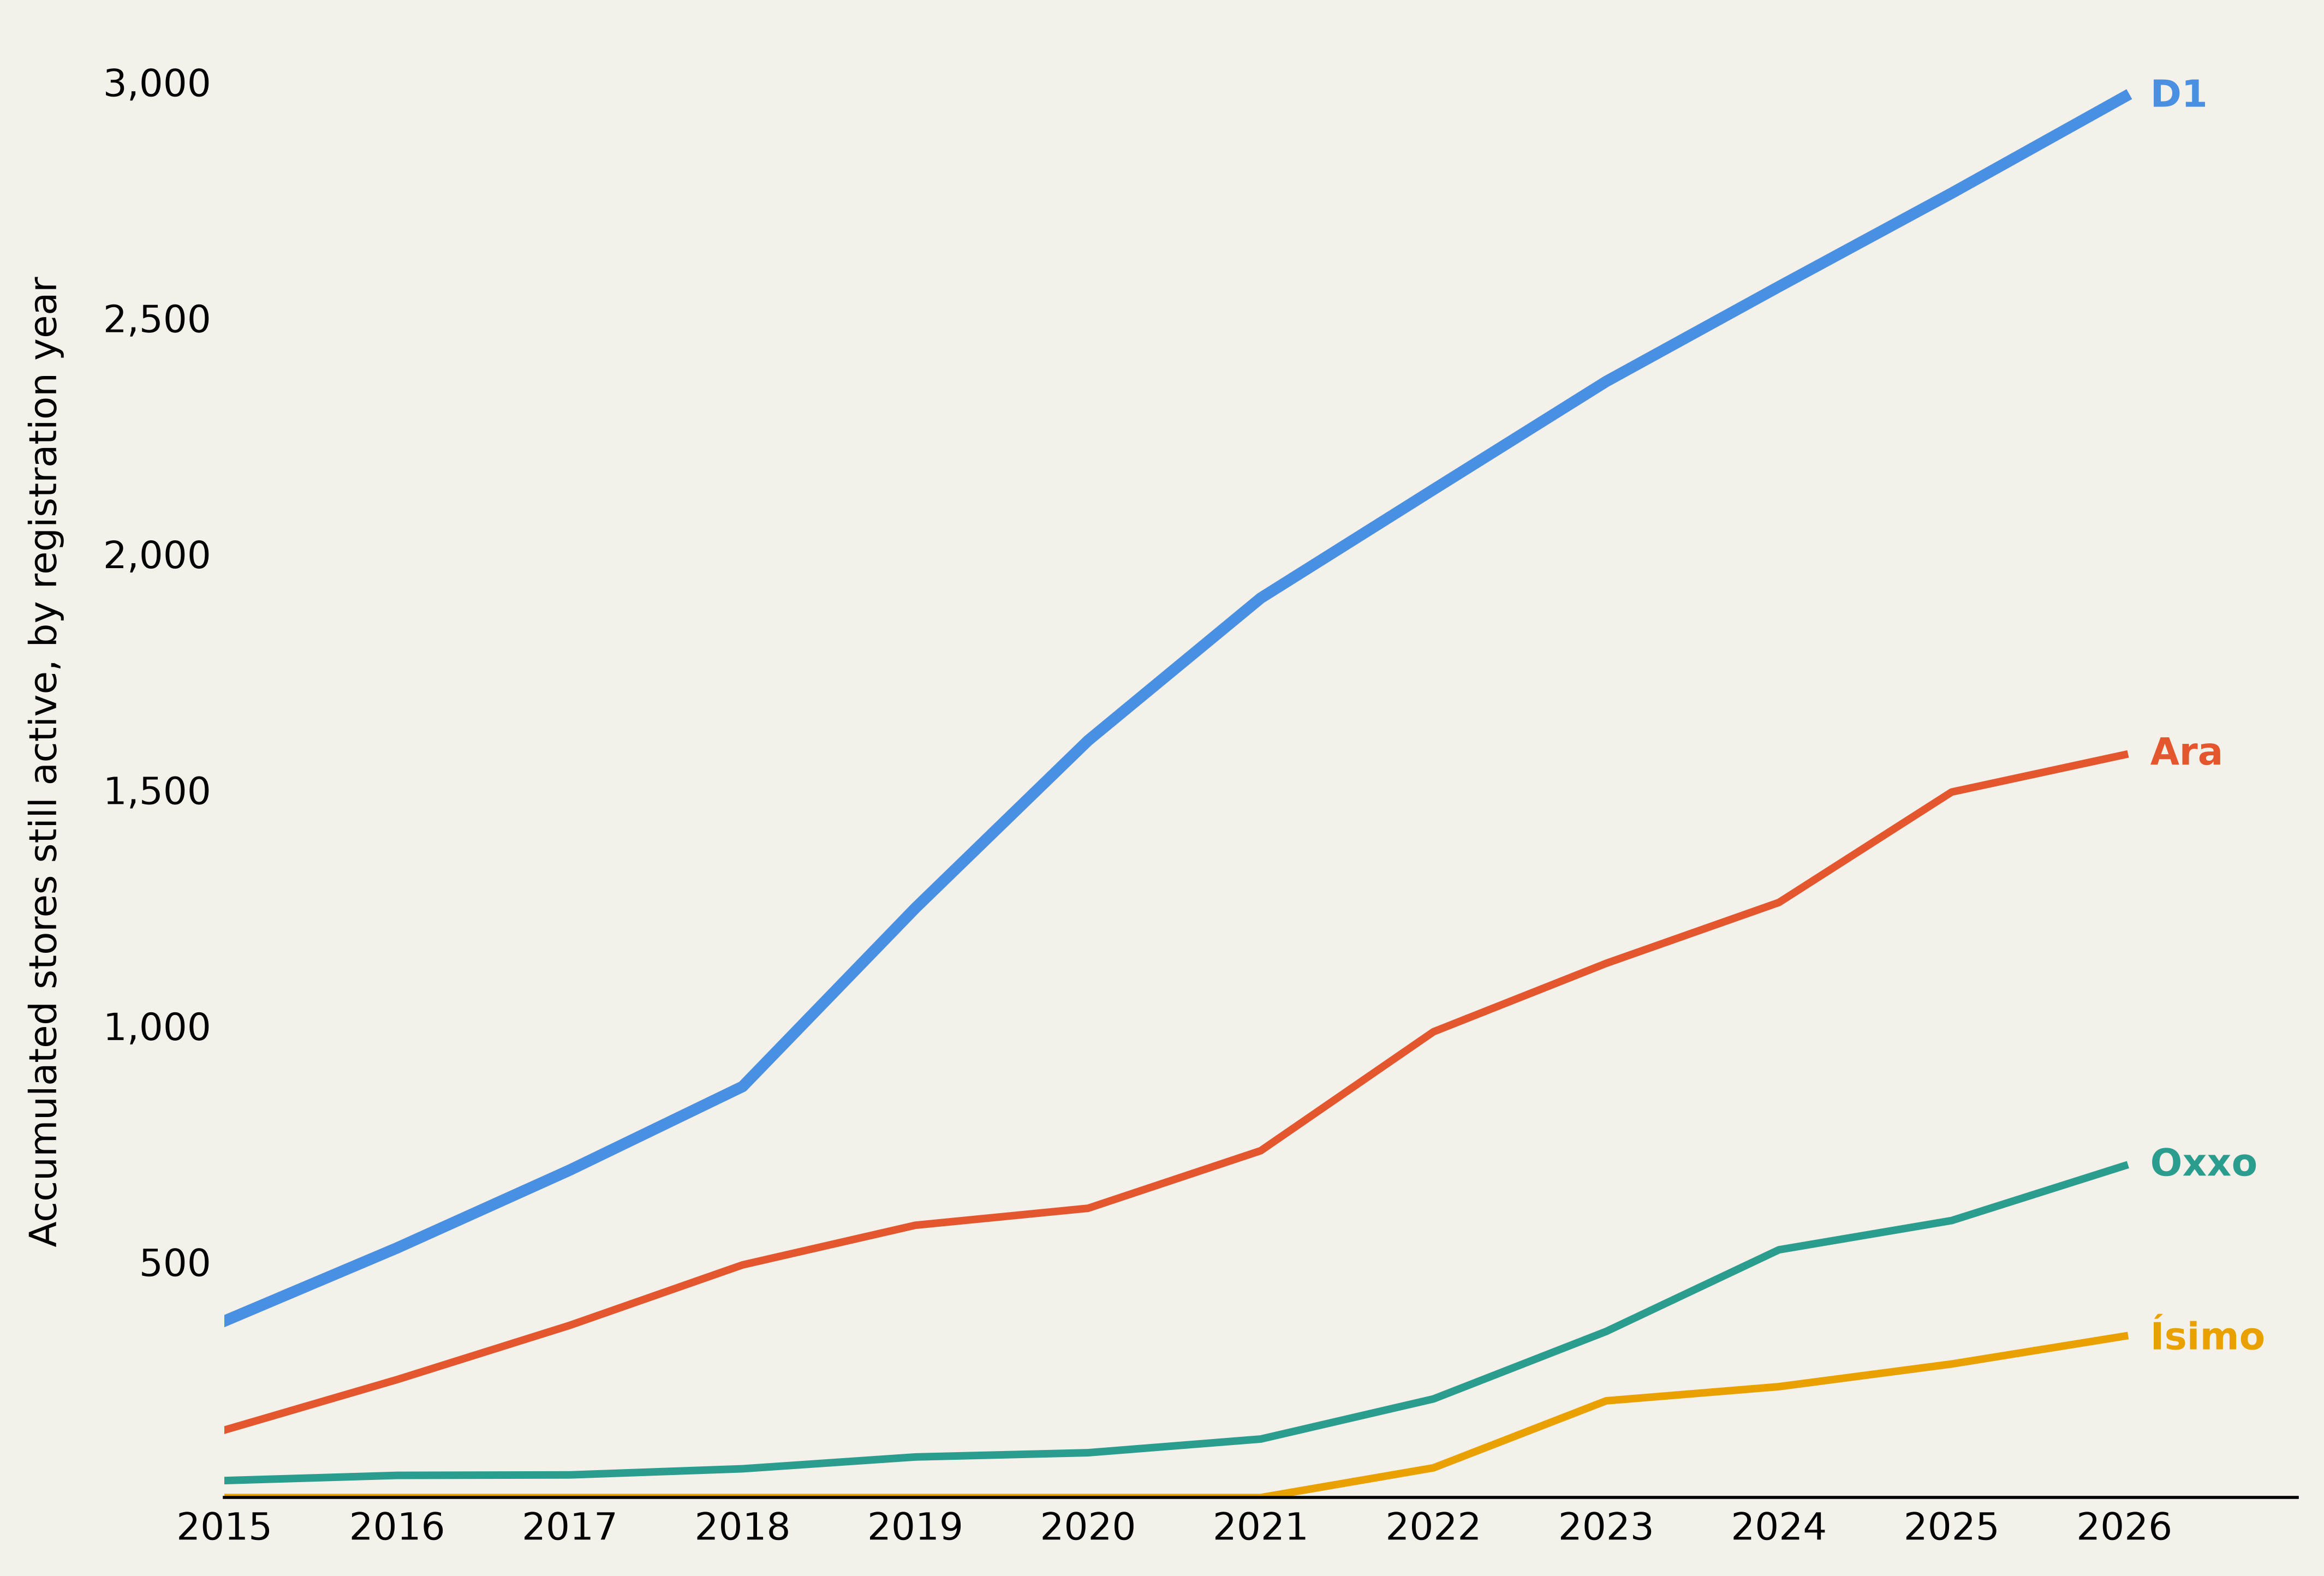

In [10]:
palette = {"D1": highlight, "Ara": "#E4572E", "Oxxo": "#2A9D8F", "Ísimo": "#E9A100"}
growth = (
    stores[stores["brand"].isin(palette) & stores["year"].between(1, 2026)]
    .groupby(["year", "brand"]).size().unstack(fill_value=0).reindex(range(1900, 2027), fill_value=0)
    .cumsum().loc[2015:]
)

plt.figure(figsize=(9.8, 7.0), dpi=500, facecolor=background)
plt.gca().set_facecolor(background)

for brand, color in palette.items():
    plt.plot(growth.index, growth[brand], color=color, linewidth=3 if brand == "D1" else 2)
    plt.text(2026.15, growth[brand].iloc[-1], f"{brand}", color=color, va="center", fontweight="bold")

for side in ["top", "right", "left"]:
    plt.gca().spines[side].set_visible(False)

plt.tick_params(axis="both", length=0)
plt.xlim(2015, 2027)
plt.ylim(0)
plt.xticks(range(2015, 2027))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:,.0f}" if y != 0 else ""))
plt.gca().set_axisbelow(True)
plt.ylabel("Accumulated stores still active, by registration year", labelpad=10, fontsize=10)

plt.show()